In [2]:
# Proyecto: Análisis de emisiones de CO2 en Colombia

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid")

# Subir el archivo CSV desde el computador
uploaded = files.upload()

# Leer el archivo seleccionado
nombre_archivo = next(iter(uploaded))
df = pd.read_csv(nombre_archivo)

# Mostrar los primeros registros
print("Primeras filas:")
display(df.head())

print("Dimensiones:", df.shape)
print("Columnas:", df.columns.tolist())


Saving annual-co2-emissions-per-country.csv to annual-co2-emissions-per-country.csv
Primeras filas:


,Entity,Code,Year,Annual CO₂ emissions
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,80608.0
2,Afghanistan,AFG,1951,87936.0
3,Afghanistan,AFG,1952,87936.0
4,Afghanistan,AFG,1953,98928.0


Dimensiones: (30219, 4)
Columnas: ['Entity', 'Code', 'Year', 'Annual CO₂ emissions']


In [3]:
# PASO 3: Filtrar los datos de Colombia

# Seleccionar únicamente Colombia
colombia = df[df["Code"] == "COL"].copy()

# Ordenar los datos por año
colombia = colombia.sort_values(by="Year")

# Reiniciar los índices
colombia = colombia.reset_index(drop=True)

# Mostrar los primeros registros
print("Primeros registros de Colombia:")
display(colombia.head(10))

# Mostrar los últimos registros
print("Últimos registros de Colombia:")
display(colombia.tail(10))

# Información general
print("Cantidad de registros:", len(colombia))
print("Año inicial:", colombia["Year"].min())
print("Año final:", colombia["Year"].max())


Primeros registros de Colombia:


,Entity,Code,Year,Annual CO₂ emissions
0,Colombia,COL,1856,9721.0
1,Colombia,COL,1857,18205.0
2,Colombia,COL,1858,20021.0
3,Colombia,COL,1859,5276.0
4,Colombia,COL,1860,9308.0
5,Colombia,COL,1861,12190.0
6,Colombia,COL,1862,27600.0
7,Colombia,COL,1863,24381.0
8,Colombia,COL,1864,19421.0
9,Colombia,COL,1865,10026.0


Últimos registros de Colombia:


,Entity,Code,Year,Annual CO₂ emissions
160,Colombia,COL,2016,94734020.0
161,Colombia,COL,2017,74439500.0
162,Colombia,COL,2018,89217440.0
163,Colombia,COL,2019,101931830.0
164,Colombia,COL,2020,93628830.0
165,Colombia,COL,2021,103414850.0
166,Colombia,COL,2022,101543710.0
167,Colombia,COL,2023,105349000.0
168,Colombia,COL,2024,106288370.0
169,Colombia,COL,2025,96066940.0


Cantidad de registros: 170
Año inicial: 1856
Año final: 2025


In [4]:
# PASO 5: Limpieza de datos

# Crear una copia para conservar los datos originales
colombia_limpio = colombia.copy()

# Convertir las columnas a valores numéricos
colombia_limpio["Year"] = pd.to_numeric(
    colombia_limpio["Year"], errors="coerce"
)

colombia_limpio["Annual CO₂ emissions"] = pd.to_numeric(
    colombia_limpio["Annual CO₂ emissions"], errors="coerce"
)

# Mostrar la cantidad de registros antes de limpiar
print("Registros antes:", len(colombia_limpio))

# Eliminar registros con años o emisiones faltantes
colombia_limpio = colombia_limpio.dropna(
    subset=["Year", "Annual CO₂ emissions"]
)

# Eliminar filas completamente duplicadas
colombia_limpio = colombia_limpio.drop_duplicates()

# Comprobar que no existan años repetidos
if colombia_limpio["Year"].duplicated().any():
    raise ValueError("Existen años duplicados. Revisar antes de continuar.")

# Eliminar registros con emisiones negativas
colombia_limpio = colombia_limpio[
    colombia_limpio["Annual CO₂ emissions"] >= 0
]

# Organizar los datos cronológicamente
colombia_limpio = colombia_limpio.sort_values("Year")
colombia_limpio = colombia_limpio.reset_index(drop=True)

# Resultados
print("Registros después:", len(colombia_limpio))
print("Valores nulos restantes:")
print(colombia_limpio.isnull().sum())

display(colombia_limpio.head())

Registros antes: 170
Registros después: 170
Valores nulos restantes:
Entity                  0
Code                    0
Year                    0
Annual CO₂ emissions    0
dtype: int64


,Entity,Code,Year,Annual CO₂ emissions
0,Colombia,COL,1856,9721.0
1,Colombia,COL,1857,18205.0
2,Colombia,COL,1858,20021.0
3,Colombia,COL,1859,5276.0
4,Colombia,COL,1860,9308.0


In [5]:

# Guardar la base de datos limpia

colombia_limpio.to_csv(
    "emisiones_co2_colombia_limpio.csv",
    index=False
)

print("Archivo CSV limpio guardado correctamente.")

Archivo CSV limpio guardado correctamente.


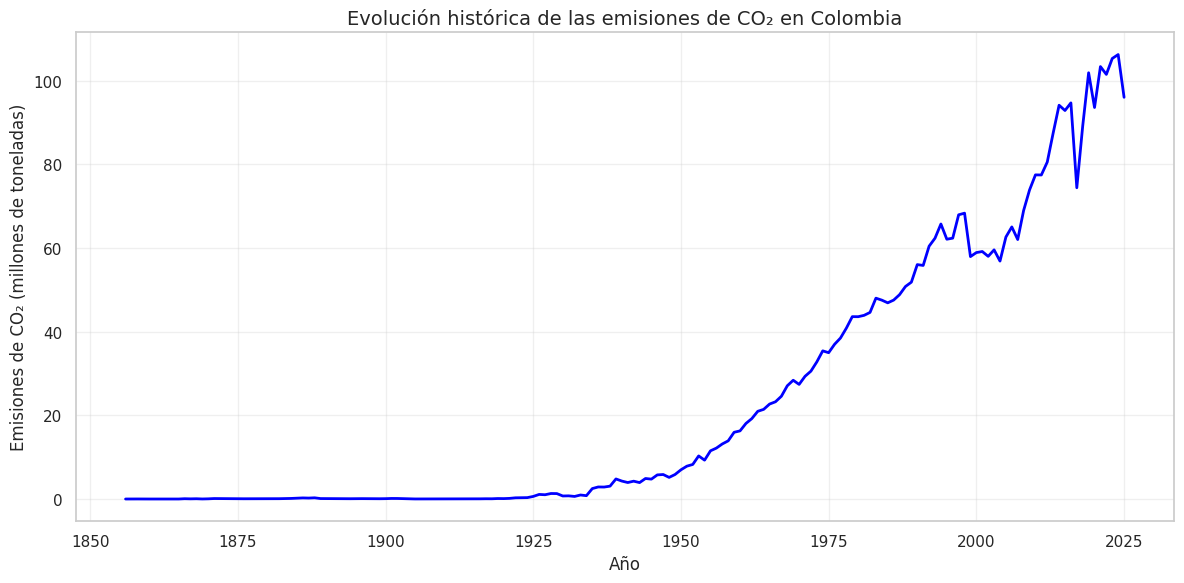

In [6]:
# PASO 7: Evolución histórica de las emisiones de CO2

plt.figure(figsize=(12, 6))

plt.plot(
    colombia_limpio["Year"],
    colombia_limpio["Annual CO₂ emissions"] / 1_000_000,
    color="blue",
    linewidth=2
)

plt.title(
    "Evolución histórica de las emisiones de CO₂ en Colombia",
    fontsize=14
)

plt.xlabel("Año")
plt.ylabel("Emisiones de CO₂ (millones de toneladas)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Análisis del comportamiento de las emisiones de CO₂ en Colombia

Al observar la gráfica, se puede identificar que las emisiones de CO₂ en Colombia han aumentado considerablemente entre 1856 y 2025. Durante las primeras décadas, los niveles de contaminación registrados fueron bastante bajos y se mantuvieron sin grandes cambios. No obstante, desde mediados del siglo XX se empezó a presentar un incremento más notable.Entre 1950 y 2000, las emisiones crecieron de manera constante. A partir del año 2000, se pueden observar algunas subidas y bajadas, destacándose una caída importante alrededor de 2020. Después de este periodo, las emisiones volvieron a aumentar y alcanzaron valores superiores a los 100 millones de toneladas anuales.En los últimos años, aunque se han registrado algunos descensos, las emisiones continúan siendo mucho mayores en comparación con las de décadas anteriores.En general, los resultados muestran que las emisiones de CO₂ en Colombia han tenido un crecimiento importante a lo largo de su historia, lo que demuestra la necesidad de prestar atención a esta problemática ambiental y buscar alternativas que permitan disminuirlas.